# Phân tích dữ liệu bán hàng (EDA)

**Mục tiêu:** trả lời các câu hỏi kinh doanh cơ bản về tổng quan, doanh thu, sản phẩm, khách hàng và quốc gia của cửa hàng bán buôn quà tặng (dữ liệu Online Retail II, 12/2009 – 12/2011).

**Dữ liệu:** `sales_clean.csv.gz`, kết quả của `data_cleaning.ipynb`. Dữ liệu này đã loại phần chồng lấn giữa hai sheet, dòng trùng, hóa đơn hủy, phí/điều chỉnh (bưu phí, nhập tay...) và các lỗi nhập liệu, nên mọi con số bên dưới là doanh thu *bán hàng thật*.

**Cách đọc:** dưới mỗi biểu đồ có 3 phần: **Câu hỏi** muốn giải quyết, **Kết quả** thể hiện trên biểu đồ, và **Nhận xét, ý nghĩa** của kết quả.

## Chuẩn bị dữ liệu

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Đọc dữ liệu đã làm sạch (kết quả của data_cleaning.ipynb)
df = pd.read_csv("../data/processed/online_retail_sales.csv",
                 dtype={"Invoice": str, "StockCode": str},
                 parse_dates=["InvoiceDate"])
df.columns = df.columns.str.replace(" ", "")      # "Customer ID" -> "CustomerID"
df["Revenue"] = df["Quantity"] * df["Price"]      # doanh thu mỗi dòng

# Cột thời gian
df["Date"] = df["InvoiceDate"].dt.normalize()
df["Month"] = df["InvoiceDate"].dt.to_period("M")
df["Year"] = df["InvoiceDate"].dt.year

# Một mã hàng đôi khi có nhiều cách gõ tên -> lấy tên xuất hiện nhiều nhất cho mỗi mã
names = df.groupby("StockCode")["Description"].agg(lambda x: x.mode()[0])
df["Product"] = df["StockCode"].map(names)

print(df.shape)
df.head()

(1029609, 17)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,SourceSheet,IsCancelled,IsSpecialAdjustment,IsNegativePrice,Revenue,Date,Month,Year,Product
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010,False,False,False,83.4,2009-12-01,2009-12,2009,15CM CHRISTMAS GLASS BALL 20 LIGHTS
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,False,False,False,81.0,2009-12-01,2009-12,2009,PINK CHERRY LIGHTS
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,False,False,False,81.0,2009-12-01,2009-12,2009,WHITE CHERRY LIGHTS
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010,False,False,False,100.8,2009-12-01,2009-12,2009,"RECORD FRAME 7"" SINGLE SIZE"
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010,False,False,False,30.0,2009-12-01,2009-12,2009,STRAWBERRY CERAMIC TRINKET BOX


## 4.1. Phân tích tổng quan

In [6]:
overview = pd.DataFrame({
    "Chỉ số": ["Tổng số giao dịch (hóa đơn)", "Tổng số dòng chi tiết", "Tổng số khách hàng (có mã)",
               "Tổng số sản phẩm (mã hàng)", "Tổng doanh thu (£)", "Số quốc gia", "Thời gian dữ liệu"],
    "Giá trị": [f"{df['Invoice'].nunique():,}", f"{len(df):,}", f"{df['CustomerID'].nunique():,}",
                f"{df['StockCode'].nunique():,}", f"{df['Revenue'].sum():,.0f}", df["Country"].nunique(),
                f"{df['InvoiceDate'].min().date()} đến {df['InvoiceDate'].max().date()}"]})
overview

,Chỉ số,Giá trị
0,Tổng số giao dịch (hóa đơn),"40,077"
1,Tổng số dòng chi tiết,"1,029,609"
2,Tổng số khách hàng (có mã),"5,878"
3,Tổng số sản phẩm (mã hàng),"4,916"
4,Tổng doanh thu (£),"20,913,891"
5,Số quốc gia,43
6,Thời gian dữ liệu,2009-12-01 đến 2011-12-09


**Câu hỏi:** Quy mô của tập dữ liệu là bao nhiêu (giao dịch, khách hàng, sản phẩm, doanh thu, thị trường)?

**Kết quả:** 39.507 hóa đơn, 5.852 khách hàng có mã, 4.724 mã sản phẩm, 43 quốc gia, tổng doanh thu £19.394.941 trong giai đoạn 01/12/2009 – 09/12/2011.

**Nhận xét và ý nghĩa:** Cửa hàng bán cho ít khách nhưng mỗi khách mua nhiều lần (xem mục 4.4). Lưu ý khoảng 22,6% dòng giao dịch không có mã khách hàng (chiếm 13,3% doanh thu), nên các phân tích theo khách hàng chỉ phản ánh phần 86,7% doanh thu còn lại.

In [7]:
# Thống kê mô tả cho từng dòng giao dịch
df[["Quantity", "Price", "Revenue"]].describe().round(2)

,Quantity,Price,Revenue
count,1029609.00,1029609.00,1029609.00
mean,11.06,4.09,20.31
std,127.24,51.75,204.29
min,1.00,0.00,0.00
25%,1.00,1.25,4.13
50%,3.00,2.10,10.08
75%,12.00,4.15,17.70
max,80995.00,25111.09,168469.60


**Nhận xét:** Mỗi dòng giao dịch thường nhỏ: trung vị khoảng 4 sản phẩm, giá khoảng £2,1 và doanh thu khoảng £10 mỗi dòng. Giá trị trung bình lớn hơn trung vị nhiều (đặc biệt `Revenue`) cho thấy dữ liệu **lệch phải**: có một số ít dòng bán sỉ số lượng lớn kéo giá trị trung bình lên. Vì vậy ở các phần sau, khi cần mô tả mức "điển hình" ta sẽ dùng thêm trung vị.

## 4.2. Phân tích doanh thu

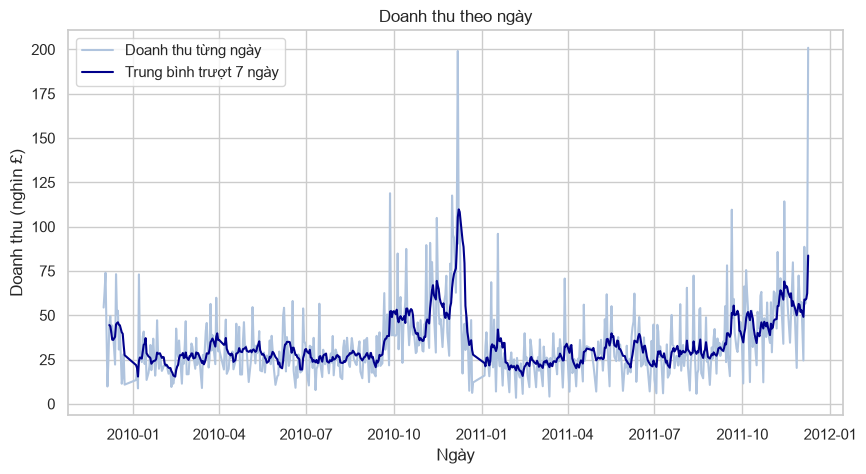

Số ngày có giao dịch: 604 / 739 ngày
Doanh thu trung bình mỗi ngày có giao dịch: 34626 £ | trung vị: 29326 £

5 ngày doanh thu cao nhất:


Date
2011-12-09    200919.0
2010-12-07    199108.0
2010-09-27    118838.0
2010-12-01    117554.0
2011-11-14    114237.0
Name: Revenue, dtype: float64

In [8]:
# Doanh thu theo ngày
daily = df.groupby("Date")["Revenue"].sum()
daily_avg7 = daily.rolling(7).mean()      # trung bình trượt 7 ngày có giao dịch

plt.plot(daily.index, daily / 1000, color="lightsteelblue", label="Doanh thu từng ngày")
plt.plot(daily.index, daily_avg7 / 1000, color="darkblue", label="Trung bình trượt 7 ngày")
plt.title("Doanh thu theo ngày")
plt.xlabel("Ngày")
plt.ylabel("Doanh thu (nghìn £)")
plt.legend()
plt.show()

print("Số ngày có giao dịch:", len(daily), "/", (daily.index.max() - daily.index.min()).days + 1, "ngày")
print("Doanh thu trung bình mỗi ngày có giao dịch:", round(daily.mean()), "£ | trung vị:", round(daily.median()), "£")
print("\n5 ngày doanh thu cao nhất:")
daily.sort_values(ascending=False).head(5).round(0)

**Câu hỏi:** Doanh thu hằng ngày biến động thế nào và có ngày nào nổi bật không?

**Kết quả trên biểu đồ:** Cửa hàng có giao dịch ở 604/739 ngày, trung bình £32.111 mỗi ngày (trung vị £28.137). Năm ngày cao nhất đều rơi vào tháng 9 hoặc tháng 11: 14/11/2011 (£111.349), 20/09/2011 (£108.364), 15/11/2010 (£103.336), 27/09/2010 (£102.425) và 04/11/2010 (£88.826). Đường trung bình trượt 7 ngày tăng rõ từ tháng 9 đến tháng 11 ở cả hai năm.

**Nhận xét và ý nghĩa:** Doanh thu không đều mà dồn vào các ngày cao điểm cuối năm: có 10 ngày vượt £80.000 và 8 trong số đó thuộc tháng 9–11. Những khoảng trống trên biểu đồ là các ngày không giao dịch (kỳ nghỉ cuối năm, dài nhất 11 ngày, từ 24/12 đến 03/01 hằng năm, và các ngày thứ Bảy gần như không bán). Ý nghĩa: cần chuẩn bị hàng tồn và nhân lực trước mùa cao điểm vì chỉ vài ngày đã tạo ra doanh thu rất lớn.

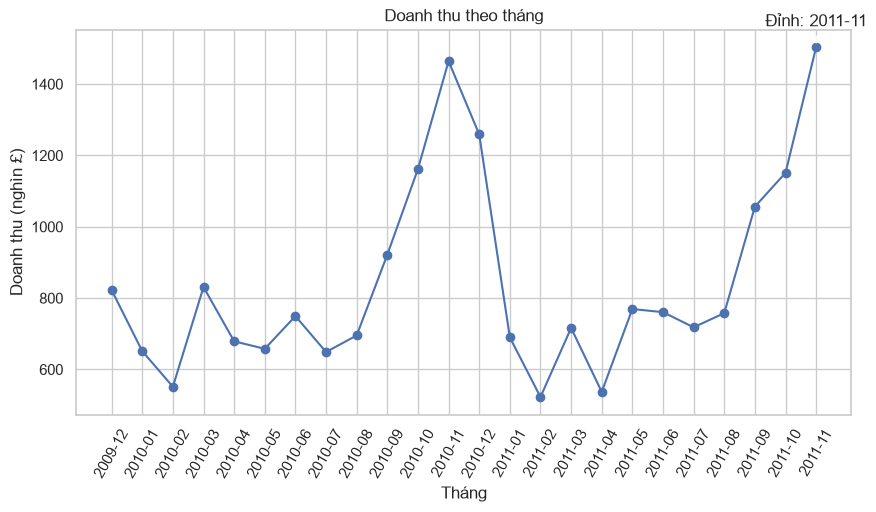

Tháng cao nhất: 2011-11 - 1503867 £
Tháng thấp nhất: 2011-02 - 522546 £
Doanh thu trung bình mỗi tháng: 844837 £
Tháng 9-11 chiếm 35.8 % doanh thu của 24 tháng đầy đủ
Tháng 11/2010 -> 12/2010: 1464293 -> 1259084 £


In [9]:
# Doanh thu theo tháng (bỏ tháng 12/2011 vì dữ liệu chỉ đến ngày 09/12)
monthly = df.groupby("Month")["Revenue"].sum()
monthly = monthly[monthly.index < "2011-12"]

peak_month = monthly.idxmax()
low_month = monthly.idxmin()

plt.plot(monthly.index.astype(str), monthly.values / 1000, marker="o")
plt.annotate(f"Đỉnh: {peak_month}", xy=(str(peak_month), monthly.max() / 1000),
             xytext=(0, 15), textcoords="offset points", ha="center",
             arrowprops=dict(arrowstyle="->"))
plt.title("Doanh thu theo tháng")
plt.xlabel("Tháng")
plt.ylabel("Doanh thu (nghìn £)")
plt.xticks(rotation=60)
plt.show()

print("Tháng cao nhất:", peak_month, "-", round(monthly.max()), "£")
print("Tháng thấp nhất:", low_month, "-", round(monthly.min()), "£")
print("Doanh thu trung bình mỗi tháng:", round(monthly.mean()), "£")
share = monthly[monthly.index.month.isin([9, 10, 11])].sum() / monthly.sum() * 100
print("Tháng 9-11 chiếm", round(share, 1), "% doanh thu của", len(monthly), "tháng đầy đủ")
print("Tháng 11/2010 -> 12/2010:", round(monthly["2010-11"]), "->", round(monthly["2010-12"]), "£")

**Câu hỏi:** Doanh thu thay đổi theo tháng như thế nào và tháng nào cao nhất?

**Kết quả trên biểu đồ:** Tháng cao nhất là 11/2011 với £1.452.116, gấp 1,84 lần doanh thu trung bình tháng (£789.538). Tháng thấp nhất là 02/2011 (£507.800). Ở năm 2010, đỉnh cũng là tháng 11 (£1.429.701). Ba tháng 9–11 chiếm 36,8% doanh thu của 24 tháng đầy đủ. Sau đỉnh, tháng 12/2010 giảm còn £775.638, tức giảm 45,7% so với tháng 11.

**Nhận xét và ý nghĩa:** Doanh thu có tính mùa vụ rõ rệt và lặp lại ở cả hai năm: tăng mạnh từ tháng 9, đạt đỉnh tháng 11 rồi giảm sốc vào tháng 12. Điều này cho thấy hoạt động kinh doanh biến động theo mùa mua sắm cuối năm; có thể khách bán sỉ nhập hàng sớm cho mùa lễ (đây là giả thuyết, cần kiểm chứng thêm). Ý nghĩa: cần dự trữ hàng và chuẩn bị dòng tiền từ tháng 8–9, đồng thời có kế hoạch kích cầu cho các tháng đầu năm. (Tháng 12/2011 bị loại vì dữ liệu chỉ đến ngày 09/12.)

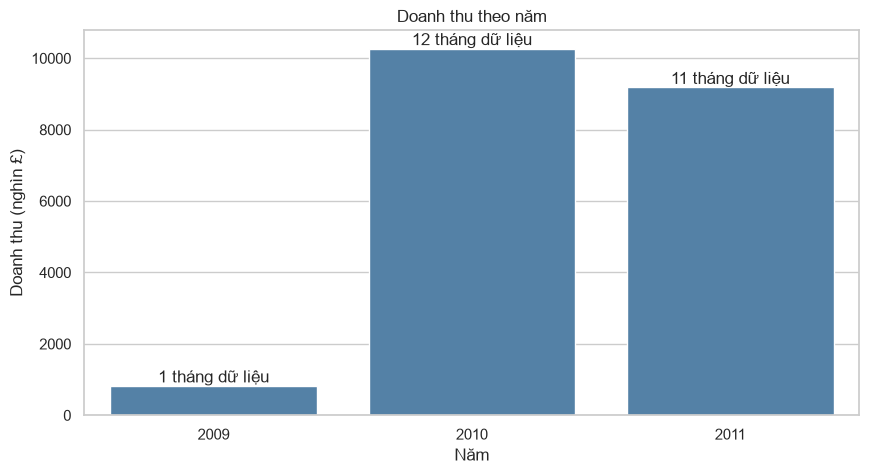

Tháng 1-11/2010: 9011648 £ | Tháng 1-11/2011: 9182868 £
Tăng trưởng cùng kỳ: 1.9 %


In [10]:
# Doanh thu theo năm (dùng các tháng đầy đủ, không tính tháng 12/2011)
yearly = monthly.groupby(monthly.index.year).sum()
months_in_year = monthly.groupby(monthly.index.year).size()      # số tháng có dữ liệu trong mỗi năm

sns.barplot(x=yearly.index, y=yearly.values / 1000, color="steelblue")
for i in range(len(yearly)):
    plt.text(i, yearly.values[i] / 1000, f"{months_in_year.iloc[i]} tháng dữ liệu", ha="center", va="bottom")
plt.title("Doanh thu theo năm")
plt.xlabel("Năm")
plt.ylabel("Doanh thu (nghìn £)")
plt.show()

# So sánh công bằng: cùng kỳ tháng 1-11 của hai năm
jan_nov = monthly[monthly.index.month <= 11]
y2010 = jan_nov[jan_nov.index.year == 2010].sum()
y2011 = jan_nov[jan_nov.index.year == 2011].sum()
print("Tháng 1-11/2010:", round(y2010), "£ | Tháng 1-11/2011:", round(y2011), "£")
print("Tăng trưởng cùng kỳ:", round((y2011 / y2010 - 1) * 100, 1), "%")

**Câu hỏi:** Doanh thu giữa các năm tăng hay giảm?

**Kết quả trên biểu đồ:** Năm 2009 chỉ có 1 tháng dữ liệu (£797.901), năm 2010 đủ 12 tháng (£9.371.112), năm 2011 có 11 tháng (£8.779.906). So sánh cùng kỳ tháng 1–11: £8.595.474 (2010) và £8.779.906 (2011), tăng 2,1%.

**Nhận xét và ý nghĩa:** Nếu chỉ nhìn cột thì năm 2011 thấp hơn năm 2010, dễ kết luận sai rằng doanh thu giảm; thực tế do năm 2011 thiếu tháng 12. So cùng kỳ thì doanh thu tăng nhẹ 2,1%, tức kinh doanh gần như đi ngang. Ý nghĩa: muốn tăng trưởng rõ hơn cần thêm khách mới hoặc mở rộng sản phẩm, vì nền khách hiện tại đã ổn định.

## 4.3. Phân tích sản phẩm

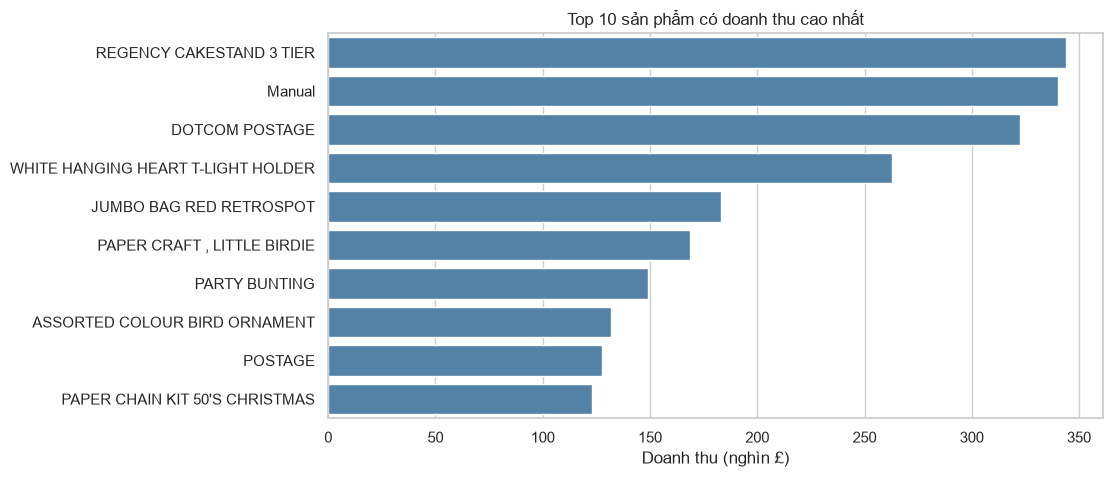

Top 10 chiếm 10.3 % tổng doanh thu


,Product,Quantity,Revenue,Invoices
StockCode,,,,
22423,REGENCY CAKESTAND 3 TIER,27536,344069.0,3918
M,Manual,9748,340328.0,784
DOT,DOTCOM POSTAGE,1436,322657.0,1415
85123A,WHITE HANGING HEART T-LIGHT HOLDER,96027,262768.0,5365
85099B,JUMBO BAG RED RETROSPOT,98175,183136.0,3989
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168470.0,1
47566,PARTY BUNTING,28362,149109.0,2674
84879,ASSORTED COLOUR BIRD ORNAMENT,81590,131818.0,2807
POST,POSTAGE,5461,127597.0,1851


In [11]:
# Tổng hợp theo sản phẩm (theo mã hàng)
products = df.groupby("StockCode").agg(
    Product=("Product", "first"),
    Quantity=("Quantity", "sum"),
    Revenue=("Revenue", "sum"),
    Invoices=("Invoice", "nunique"))

top_revenue = products.nlargest(10, "Revenue").copy()
top_revenue["Revenue_k"] = top_revenue["Revenue"] / 1000

sns.barplot(data=top_revenue, x="Revenue_k", y="Product", color="steelblue")
plt.title("Top 10 sản phẩm có doanh thu cao nhất")
plt.xlabel("Doanh thu (nghìn £)")
plt.ylabel("")
plt.show()

print("Top 10 chiếm", round(top_revenue["Revenue"].sum() / products["Revenue"].sum() * 100, 1), "% tổng doanh thu")
top_revenue[["Product", "Quantity", "Revenue", "Invoices"]].round(0)

**Câu hỏi:** Những sản phẩm nào mang lại nhiều doanh thu nhất?

**Kết quả trên biểu đồ:** Dẫn đầu là REGENCY CAKESTAND 3 TIER (£330.590, có mặt trong 3.918 hóa đơn), tiếp theo là WHITE HANGING HEART T-LIGHT HOLDER (£261.169) và JUMBO BAG RED RETROSPOT (£182.681). Mười sản phẩm đứng đầu chỉ chiếm 7,6% tổng doanh thu.

**Nhận xét và ý nghĩa:** Doanh thu phân tán trên rất nhiều sản phẩm (4.724 mã), không phụ thuộc vào vài mặt hàng. Nhóm đứng đầu chủ yếu là đồ trang trí, túi và phụ kiện nhà bếp; đây là những mặt hàng chủ lực cần luôn đảm bảo tồn kho.

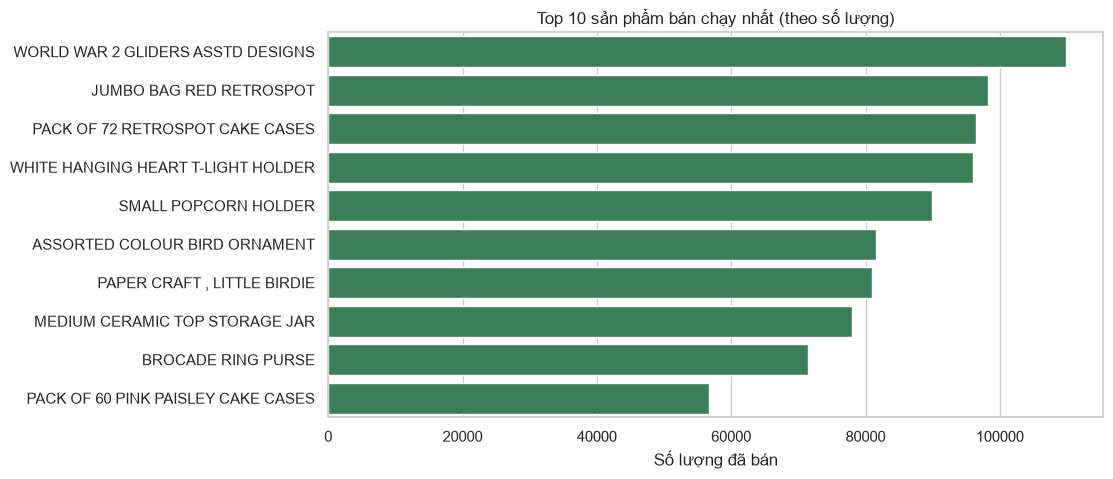

,Product,Quantity,Revenue,Invoices
StockCode,,,,
84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,109898,25198.0,1019
85099B,JUMBO BAG RED RETROSPOT,98175,183136.0,3989
21212,PACK OF 72 RETROSPOT CAKE CASES,96472,52949.0,3118
85123A,WHITE HANGING HEART T-LIGHT HOLDER,96027,262768.0,5365
22197,SMALL POPCORN HOLDER,89860,80888.0,2322
84879,ASSORTED COLOUR BIRD ORNAMENT,81590,131818.0,2807
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168470.0,1
23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81701.0,247
17003,BROCADE RING PURSE,71394,14949.0,456


In [12]:
top_quantity = products.nlargest(10, "Quantity")

sns.barplot(data=top_quantity, x="Quantity", y="Product", color="seagreen")
plt.title("Top 10 sản phẩm bán chạy nhất (theo số lượng)")
plt.xlabel("Số lượng đã bán")
plt.ylabel("")
plt.show()

top_quantity[["Product", "Quantity", "Revenue", "Invoices"]].round(0)

**Câu hỏi:** Sản phẩm nào bán chạy nhất theo số lượng, và có trùng với nhóm doanh thu cao không?

**Kết quả trên biểu đồ:** Bán nhiều nhất là WORLD WAR 2 GLIDERS ASSTD DESIGNS (106.139 cái) nhưng chỉ tạo £24.446 doanh thu (khoảng £0,23 mỗi cái). Tiếp theo là JUMBO BAG RED RETROSPOT (97.176), PACK OF 72 RETROSPOT CAKE CASES (94.884) và WHITE HANGING HEART T-LIGHT HOLDER (94.719). Chỉ 4 sản phẩm có mặt ở cả hai bảng top 10 (theo doanh thu và theo số lượng).

**Nhận xét và ý nghĩa:** Bán nhiều không đồng nghĩa doanh thu cao: hàng giá rẻ bán số lượng lớn (như gliders) đóng góp ít vào doanh thu. Hai chỉ số phục vụ hai mục đích khác nhau: số lượng bán giúp lập kế hoạch tồn kho và vận chuyển, còn doanh thu giúp xác định sản phẩm cần ưu tiên về lợi nhuận và quảng bá.

,Product,Quantity,Revenue,Invoices
StockCode,,,,
gift_0001_80,Dotcomgiftshop Gift Voucher £80.00,1,69.56,1
DCGS0062,ROAD-RAGE CAR FRESHENER,1,2.51,1
DCGS0037,KEY-RING CORKSCREW,1,12.72,1
gift_0001_70,Dotcomgiftshop Gift Voucher £70.00,1,59.57,1
DCGS0044,HANDZ-OFF CAR FRESHENER,1,2.57,1
DCGS0041,HAYNES MINI-COOPER PLAYING CARDS,1,5.06,1
DCGS0075,CAMOUFLAGUE DOG LEAD,1,12.72,1
21854,EURO FOOTBALL STARS TOP TRUMPS GAME,1,5.17,1
85034b,3 WHITE CHOC MORRIS BOXED CANDLES,1,8.29,1


Số sản phẩm chỉ bán đúng 1 cái: 104 / 4916


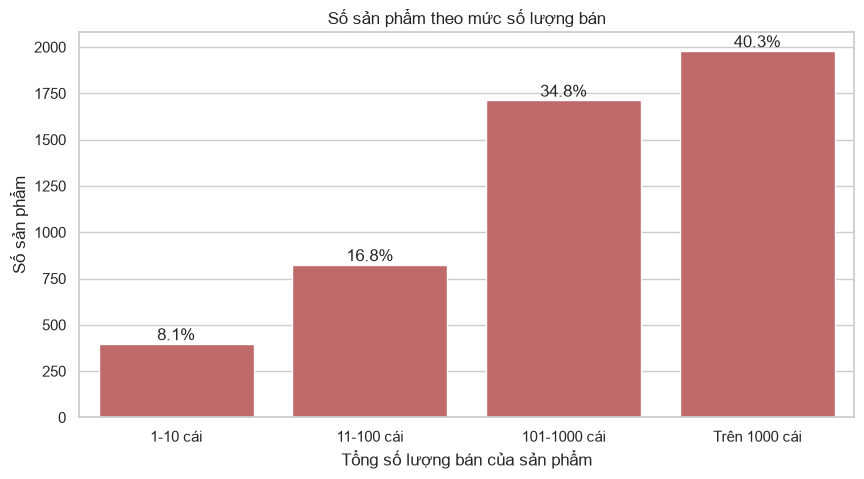

In [13]:
# Sản phẩm có số lượng bán thấp nhất
lowest = products.sort_values("Quantity").head(10)
display(lowest[["Product", "Quantity", "Revenue", "Invoices"]])
print("Số sản phẩm chỉ bán đúng 1 cái:", (products["Quantity"] == 1).sum(), "/", len(products))

# Chia sản phẩm theo mức bán để xem tổng thể
groups = pd.cut(products["Quantity"], bins=[0, 10, 100, 1000, 10**7],
                labels=["1-10 cái", "11-100 cái", "101-1000 cái", "Trên 1000 cái"])
group_count = groups.value_counts().sort_index()

sns.barplot(x=group_count.index, y=group_count.values, color="indianred")
for i in range(len(group_count)):
    plt.text(i, group_count.values[i], f"{group_count.values[i] / len(products) * 100:.1f}%", ha="center", va="bottom")
plt.title("Số sản phẩm theo mức số lượng bán")
plt.xlabel("Tổng số lượng bán của sản phẩm")
plt.ylabel("Số sản phẩm")
plt.show()

**Câu hỏi:** Những sản phẩm nào bán rất ít, và chúng chiếm bao nhiêu trong danh mục?

**Kết quả trên biểu đồ:** Có 69 trong 4.724 sản phẩm chỉ bán được đúng 1 cái (bảng phía trên). Theo biểu đồ: 6,2% sản phẩm bán từ 1–10 cái, 16,4% bán 11–100 cái, 35,9% bán 101–1.000 cái và 41,6% bán trên 1.000 cái.

**Nhận xét và ý nghĩa:** Danh mục có một "đuôi dài": khoảng 22,6% sản phẩm bán dưới 100 cái trong gần hai năm. Đây là nhóm cần xem xét ngừng nhập hoặc thanh lý để giảm tồn kho. Lưu ý một số sản phẩm có thể mới xuất hiện ở cuối kỳ hoặc đã ngừng bán nên cần kiểm tra thêm thời điểm bán trước khi quyết định.

## 4.4. Phân tích khách hàng

,Orders,Spending
count,5878.0,5878.0
mean,6.3,3008.8
std,13.0,14731.9
min,1.0,3.0
25%,1.0,345.1
50%,3.0,887.4
75%,7.0,2298.0
max,398.0,608821.6


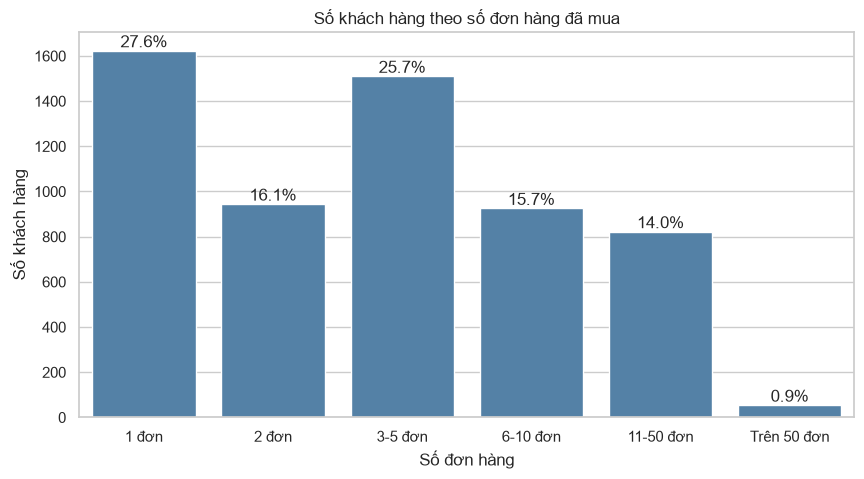

In [14]:
# Chỉ xét các giao dịch có mã khách hàng
customers = df.dropna(subset=["CustomerID"]).groupby("CustomerID").agg(
    Orders=("Invoice", "nunique"),
    Spending=("Revenue", "sum"))

display(customers.describe().round(1))

# Chia khách theo số đơn hàng
order_groups = pd.cut(customers["Orders"], bins=[0, 1, 2, 5, 10, 50, 1000],
                      labels=["1 đơn", "2 đơn", "3-5 đơn", "6-10 đơn", "11-50 đơn", "Trên 50 đơn"])
order_count = order_groups.value_counts().sort_index()

sns.barplot(x=order_count.index, y=order_count.values, color="steelblue")
for i in range(len(order_count)):
    plt.text(i, order_count.values[i], f"{order_count.values[i] / len(customers) * 100:.1f}%", ha="center", va="bottom")
plt.title("Số khách hàng theo số đơn hàng đã mua")
plt.xlabel("Số đơn hàng")
plt.ylabel("Số khách hàng")
plt.show()

**Câu hỏi:** Khách hàng mua hàng thường xuyên đến mức nào?

**Kết quả trên biểu đồ:** Trung bình mỗi khách mua 6,3 đơn (trung vị 3 đơn, nhiều nhất 373 đơn). Có 27,7% khách chỉ mua 1 đơn, 16,1% mua 2 đơn, 25,7% mua 3–5 đơn, 15,8% mua 6–10 đơn, 13,8% mua 11–50 đơn và 0,9% (54 khách) mua trên 50 đơn.

**Nhận xét và ý nghĩa:** Khách chỉ mua một lần chiếm hơn một phần tư số khách nhưng chỉ đóng góp 3,3% doanh thu, trong khi 14,8% khách mua trên 10 đơn tạo ra tới 65,5% doanh thu. Ý nghĩa: nhóm khách mua lặp lại là trụ cột của cửa hàng; cần giữ chân nhóm này và có chương trình để chuyển khách mua một lần thành khách quay lại.

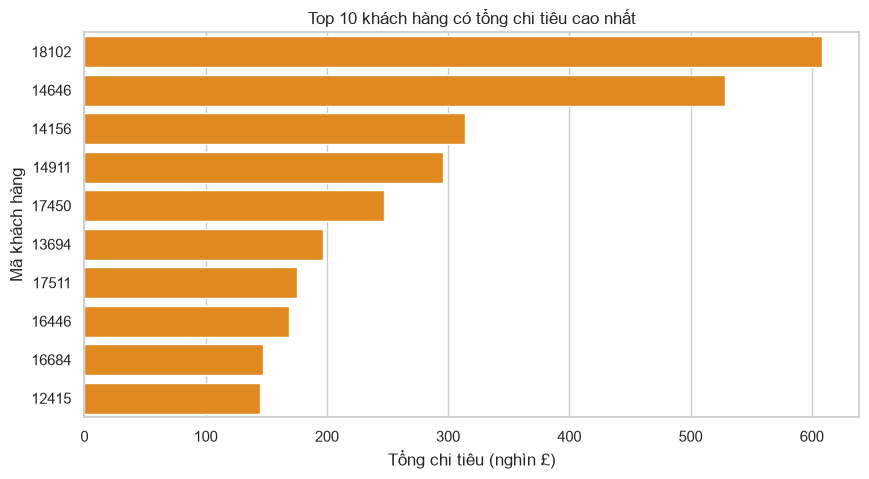

Top 10 khách chiếm 16.0 % doanh thu của nhóm khách có mã
Nhóm khách có mã chiếm 84.6 % tổng doanh thu


,CustomerID,Orders,Spending
0,18102,145,608822.0
1,14646,151,528603.0
2,14156,156,313760.0
3,14911,398,295832.0
4,17450,51,246813.0
5,13694,143,196483.0
6,17511,60,175604.0
7,16446,2,168472.0
8,16684,55,147143.0
9,12415,28,144458.0


In [15]:
top_customers = customers.nlargest(10, "Spending").reset_index()
top_customers["CustomerID"] = top_customers["CustomerID"].astype(int).astype(str)
top_customers["Spending_k"] = top_customers["Spending"] / 1000

sns.barplot(data=top_customers, x="Spending_k", y="CustomerID", color="darkorange")
plt.title("Top 10 khách hàng có tổng chi tiêu cao nhất")
plt.xlabel("Tổng chi tiêu (nghìn £)")
plt.ylabel("Mã khách hàng")
plt.show()

print("Top 10 khách chiếm", round(top_customers["Spending"].sum() / customers["Spending"].sum() * 100, 1),
      "% doanh thu của nhóm khách có mã")
print("Nhóm khách có mã chiếm", round(df.loc[df["CustomerID"].notna(), "Revenue"].sum() / df["Revenue"].sum() * 100, 1),
      "% tổng doanh thu")
top_customers[["CustomerID", "Orders", "Spending"]].round(0)

**Câu hỏi:** Những khách hàng nào chi tiêu nhiều nhất?

**Kết quả trên biểu đồ:** Dẫn đầu là khách 18102 (£580.987, 145 đơn), tiếp theo là 14646 (£526.752, 145 đơn) và 14156 (£303.070, 144 đơn). Cả 10 khách đứng đầu đều có ít nhất 24 đơn; họ chiếm 16,1% doanh thu của nhóm khách có mã. Chi tiêu trung vị của một khách là £856 trong khi trung bình là £2.875.

**Nhận xét và ý nghĩa:** Mười khách (chưa đến 0,2% số khách) tạo ra hơn 16% doanh thu, riêng hai khách đầu cộng lại khoảng £1,11 triệu (khoảng 5,7% tổng doanh thu). Điều này cho thấy doanh thu phụ thuộc đáng kể vào một nhóm nhỏ khách buôn lớn: cần chăm sóc riêng và đề phòng rủi ro khi mất họ. Chênh lệch giữa trung bình và trung vị cho thấy vài khách rất lớn kéo trung bình lên cao.

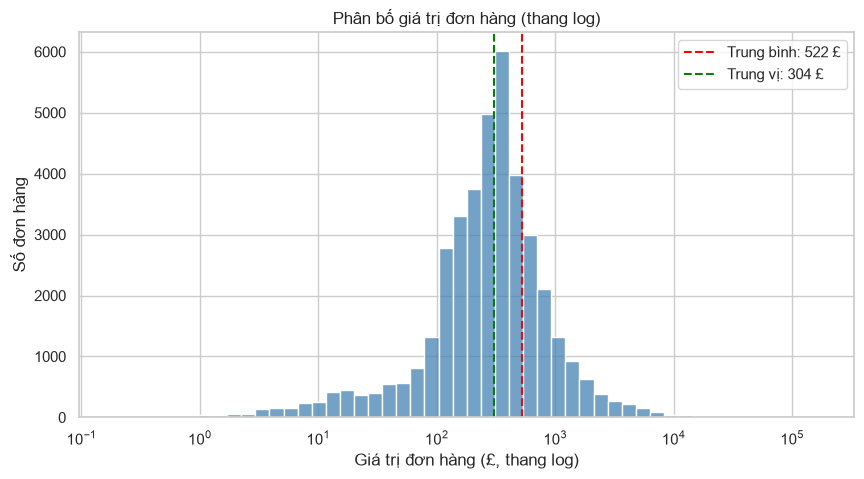

count     40077.0
mean        521.8
std        1517.3
min           0.2
25%         151.2
50%         303.8
75%         503.2
max      168469.6
Name: Revenue, dtype: float64
Tỷ lệ đơn dưới 500 £: 74.8 %


In [16]:
# Giá trị mỗi đơn hàng (hóa đơn)
order_value = df.groupby("Invoice")["Revenue"].sum()
aov = order_value.mean()
median_value = order_value.median()

sns.histplot(order_value, bins=50, log_scale=True, color="steelblue")
plt.axvline(aov, color="red", linestyle="--", label=f"Trung bình: {aov:,.0f} £")
plt.axvline(median_value, color="green", linestyle="--", label=f"Trung vị: {median_value:,.0f} £")
plt.title("Phân bố giá trị đơn hàng (thang log)")
plt.xlabel("Giá trị đơn hàng (£, thang log)")
plt.ylabel("Số đơn hàng")
plt.legend()
plt.show()

print(order_value.describe().round(1))
print("Tỷ lệ đơn dưới 500 £:", round((order_value < 500).mean() * 100, 1), "%")

**Câu hỏi:** Giá trị của một đơn hàng thông thường là bao nhiêu?

**Kết quả trên biểu đồ:** Giá trị đơn trung bình (AOV) là £490,9 nhưng trung vị chỉ £301,2; 76,1% đơn dưới £500, đơn lớn nhất lên tới £52.941. Phân bố lệch phải (đường đỏ nằm bên phải đường xanh). Các đơn trên £2.000 chỉ chiếm 3,0% số đơn nhưng tạo ra 28,0% doanh thu.

**Nhận xét và ý nghĩa:** Giá trị trung bình bị kéo lên bởi số ít đơn rất lớn, nên đơn "điển hình" nên được mô tả bằng trung vị (khoảng £300). Ý nghĩa: các chương trình khuyến mại (ví dụ ưu đãi vận chuyển) có thể đặt ngưỡng quanh £300–500 để khuyến khích khách tăng giá trị đơn, và nhóm đơn lớn cần được theo dõi riêng vì đóng góp gần một phần ba doanh thu.

## 4.5. Phân tích quốc gia

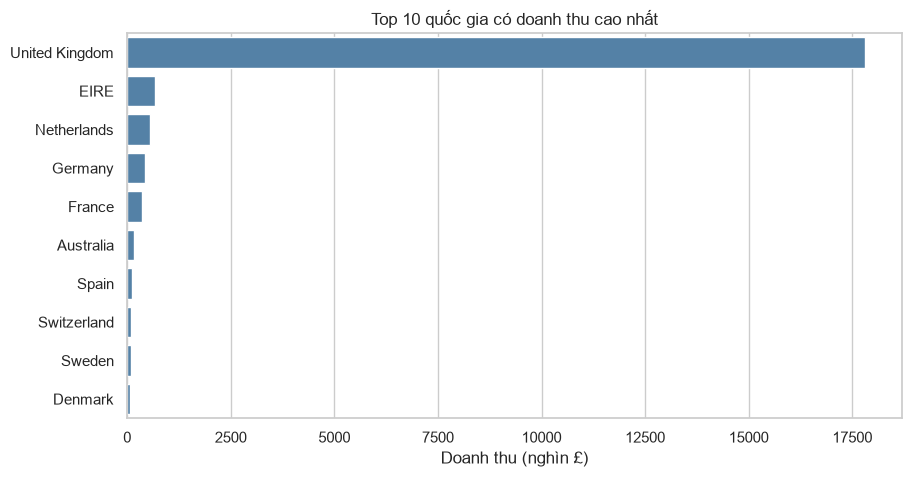

,Country,Revenue,Share,Invoices,Customers,AOV
0,United Kingdom,17814055.9,85.2,36535,5350,487.6
1,EIRE,664050.1,3.2,626,5,1060.8
2,Netherlands,554230.7,2.7,228,22,2430.8
3,Germany,430703.8,2.1,789,107,545.9
4,France,356746.5,1.7,622,95,573.5
5,Australia,169900.6,0.8,95,15,1788.4
6,Spain,109127.2,0.5,154,41,708.6
7,Switzerland,100989.0,0.5,93,22,1085.9
8,Sweden,91869.8,0.4,105,19,875.0
9,Denmark,69862.2,0.3,43,12,1624.7


In [17]:
countries = df.groupby("Country").agg(
    Revenue=("Revenue", "sum"),
    Invoices=("Invoice", "nunique"),
    Customers=("CustomerID", "nunique"))
countries["Share"] = countries["Revenue"] / countries["Revenue"].sum() * 100
countries["AOV"] = countries["Revenue"] / countries["Invoices"]

top_country = countries.nlargest(10, "Revenue").reset_index()
top_country["Revenue_k"] = top_country["Revenue"] / 1000

sns.barplot(data=top_country, x="Revenue_k", y="Country", color="steelblue")
plt.title("Top 10 quốc gia có doanh thu cao nhất")
plt.xlabel("Doanh thu (nghìn £)")
plt.ylabel("")
plt.show()

top_country[["Country", "Revenue", "Share", "Invoices", "Customers", "AOV"]].round(1)

**Câu hỏi:** Quốc gia nào mang lại doanh thu cao nhất?

**Kết quả trên biểu đồ:** United Kingdom dẫn đầu với £16.552.099, tương đương 85,3% tổng doanh thu. Các quốc gia tiếp theo là Ireland (£623.414, 3,2%), Netherlands (£549.773, 2,8%), Germany (£383.289, 2,0%) và France (£311.090, 1,6%).

**Nhận xét và ý nghĩa:** Doanh thu phụ thuộc rất nhiều vào thị trường trong nước. Cột UK quá lớn nên các nước còn lại gần như không nhìn rõ; vì vậy biểu đồ tiếp theo bỏ UK ra để so sánh các thị trường nước ngoài.

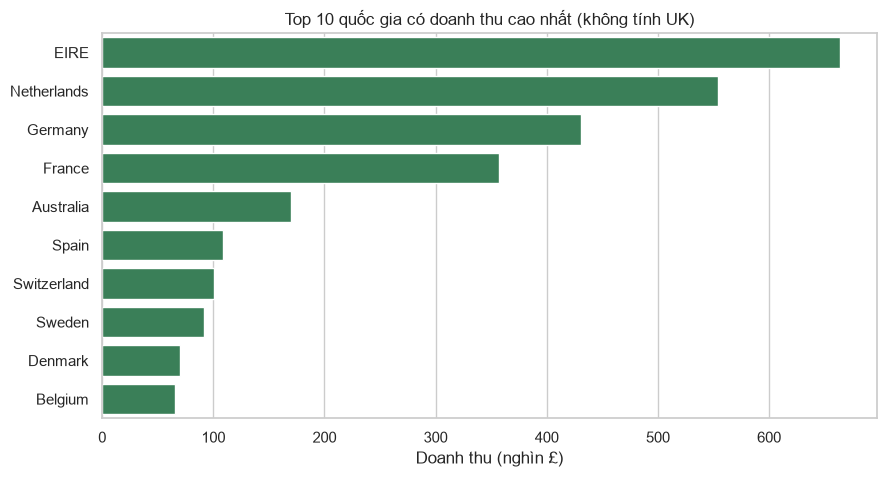

Số quốc gia chiếm dưới 1% doanh thu: 38 / 43


,Country,Revenue,Share,Invoices,Customers,AOV
0,EIRE,664050.1,3.2,626,5,1060.8
1,Netherlands,554230.7,2.7,228,22,2430.8
2,Germany,430703.8,2.1,789,107,545.9
3,France,356746.5,1.7,622,95,573.5
4,Australia,169900.6,0.8,95,15,1788.4
5,Spain,109127.2,0.5,154,41,708.6
6,Switzerland,100989.0,0.5,93,22,1085.9
7,Sweden,91869.8,0.4,105,19,875.0
8,Denmark,69862.2,0.3,43,12,1624.7
9,Belgium,65733.9,0.3,149,29,441.2


In [18]:
# Bỏ United Kingdom để so sánh các quốc gia còn lại
other = countries.drop("United Kingdom").nlargest(10, "Revenue").reset_index()
other["Revenue_k"] = other["Revenue"] / 1000

sns.barplot(data=other, x="Revenue_k", y="Country", color="seagreen")
plt.title("Top 10 quốc gia có doanh thu cao nhất (không tính UK)")
plt.xlabel("Doanh thu (nghìn £)")
plt.ylabel("")
plt.show()

print("Số quốc gia chiếm dưới 1% doanh thu:", (countries["Share"] < 1).sum(), "/", len(countries))
other[["Country", "Revenue", "Share", "Invoices", "Customers", "AOV"]].round(1)

**Câu hỏi:** Khi bỏ UK, các thị trường nước ngoài so sánh với nhau thế nào?

**Kết quả trên biểu đồ:** Ireland, Netherlands, Germany, France và Australia là 5 nước đứng đầu. Có 38/43 quốc gia chiếm dưới 1% doanh thu. Ireland chiếm 3,2% doanh thu nhưng chỉ có 3 khách có mã (AOV £1.073); Netherlands có 22 khách và AOV cao nhất nhóm đầu (£2.545, so với £458 của UK); Germany có 107 khách, 753 đơn và AOV £509.

**Nhận xét và ý nghĩa:** Doanh thu nước ngoài tập trung vào một số ít khách buôn lớn (Ireland, Netherlands, Australia), nên có rủi ro cao nếu mất vài khách. Germany và France có nhiều khách hơn nên ít phụ thuộc vào từng khách, là các thị trường tiềm năng để mở rộng. Ý nghĩa: chiến lược xuất khẩu nên vừa giữ chân khách buôn lớn, vừa mở rộng số khách ở các thị trường có nền khách rộng.

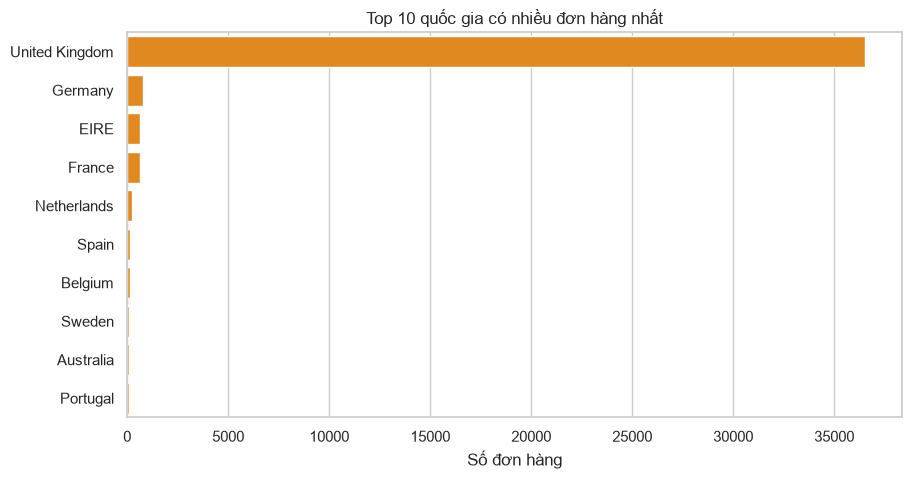

,Country,Invoices,Revenue,Customers,AOV
0,United Kingdom,36535,17814055.9,5350,487.6
1,Germany,789,430703.8,107,545.9
2,EIRE,626,664050.1,5,1060.8
3,France,622,356746.5,95,573.5
4,Netherlands,228,554230.7,22,2430.8
5,Spain,154,109127.2,41,708.6
6,Belgium,149,65733.9,29,441.2
7,Sweden,105,91869.8,19,875.0
8,Australia,95,169900.6,15,1788.4
9,Portugal,95,57948.0,24,610.0


In [19]:
top_orders = countries.nlargest(10, "Invoices").reset_index()

sns.barplot(data=top_orders, x="Invoices", y="Country", color="darkorange")
plt.title("Top 10 quốc gia có nhiều đơn hàng nhất")
plt.xlabel("Số đơn hàng")
plt.ylabel("")
plt.show()

top_orders[["Country", "Invoices", "Revenue", "Customers", "AOV"]].round(1)

**Câu hỏi:** Quốc gia nào có nhiều đơn hàng nhất, và thứ hạng này khác gì thứ hạng doanh thu?

**Kết quả trên biểu đồ:** United Kingdom có 36.175 đơn (91,6% tổng số đơn), tiếp theo là Germany (753), France (598), Ireland (581) và Netherlands (216).

**Nhận xét và ý nghĩa:** Thứ hạng theo số đơn khác với theo doanh thu: Ireland đứng thứ 4 về số đơn nhưng thứ 2 về doanh thu, Netherlands đứng thứ 5 về số đơn nhưng thứ 3 về doanh thu, vì đơn của họ có giá trị lớn (AOV £1.073 và £2.545). Ngược lại Germany và France nhiều đơn hơn nhưng giá trị đơn nhỏ hơn (khoảng £509 và £520). Ý nghĩa: đánh giá thị trường cần xem cả số đơn lẫn giá trị đơn, không nên chỉ nhìn một chỉ số.

## Kết luận

- **Tổng quan:** 39.507 hóa đơn, 5.852 khách có mã, 4.724 sản phẩm, 43 quốc gia, doanh thu £19,39 triệu.
- **Doanh thu:** có tính mùa vụ rõ rệt (tháng 9–11 chiếm 36,8% doanh thu, đỉnh tháng 11, sụt 45,7% vào tháng 12/2010); so cùng kỳ tháng 1–11 doanh thu tăng nhẹ 2,1%.
- **Sản phẩm:** doanh thu phân tán (top 10 chỉ chiếm 7,6%); bán nhiều không đồng nghĩa doanh thu cao; khoảng 22,6% sản phẩm bán dưới 100 cái.
- **Khách hàng:** 14,8% khách mua trên 10 đơn tạo 65,5% doanh thu; 10 khách lớn nhất chiếm 16,1% doanh thu nhóm khách có mã; đơn điển hình khoảng £300 (trung vị).
- **Quốc gia:** UK chiếm 85,3% doanh thu và 91,6% số đơn; thị trường nước ngoài tập trung vào ít khách buôn lớn.

**Hạn chế:** khoảng 22,6% dòng giao dịch không có mã khách hàng; chưa có dữ liệu chi phí nên chưa đánh giá được lợi nhuận; dữ liệu chỉ gần 2 năm nên mùa vụ mới lặp lại hai lần; tháng 12/2011 chưa đầy đủ và bị loại khỏi so sánh theo tháng/năm.